Project Source Code

In [3]:
import os
import glob
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

In [4]:
csv_path = "train_u6lujuX_CVtuZ9i.csv"
print("Using file:", csv_path)

Using file: train_u6lujuX_CVtuZ9i.csv


In [5]:
df = pd.read_csv(csv_path)
print("Rows, Columns:", df.shape)
df.info(memory_usage="deep")
print(df.isnull().sum().sum(), "missing values in total")
print(df.isnull().sum())
df.head()

Rows, Columns: (614, 13)
<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB
149 missing values in total
Loan_ID               0
Gender               13
Married               3
De

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [6]:
cat_cols = ["Gender", "Married", "Dependents", "Self_Employed"]
num_cols = ["LoanAmount", "Loan_Amount_Term", "Credit_History"]

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

print(df.isnull().sum().sum(), "missing values left")

0 missing values left


In [7]:
df["approved"] = (df["Loan_Status"] == "Y").astype(int)
print(df["approved"].value_counts())

approved
1    422
0    192
Name: count, dtype: int64


In [8]:
def get_dependents(cell):
    """'3+' -> 3, '1' -> 1"""
    return int(str(cell).replace("+", ""))

def yes_no(cell):
    """'Yes' -> 1, 'No' -> 0"""
    return 1 if str(cell).strip() == "Yes" else 0

def calc_emi(loan_amount, term):
    """Monthly installment (loan amount is in thousands, term is in months)"""
    return loan_amount * 1000 / term

In [9]:
df["num_dependents"] = df["Dependents"].apply(get_dependents)
df["is_married"] = df["Married"].apply(yes_no)
df["is_self_employed"] = df["Self_Employed"].apply(yes_no)
df["is_graduate"] = (df["Education"] == "Graduate").astype(int)
df["is_male"] = (df["Gender"] == "Male").astype(int)
df["has_coapplicant"] = (df["CoapplicantIncome"] > 0).astype(int)

df["total_income"] = np.log1p(df["ApplicantIncome"] + df["CoapplicantIncome"])
df["ApplicantIncome"] = np.log1p(df["ApplicantIncome"])
df["CoapplicantIncome"] = np.log1p(df["CoapplicantIncome"])
df["emi"] = df["LoanAmount"].combine(df["Loan_Amount_Term"], calc_emi)

print(df["Property_Area"].value_counts())

feature_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term",
                "Credit_History", "total_income", "emi", "num_dependents", "is_married",
                "is_self_employed", "is_graduate", "is_male", "has_coapplicant"]
X = pd.concat([df[feature_cols], pd.get_dummies(df["Property_Area"], prefix="area").astype(int)], axis=1)
y = df["approved"]
print("Feature matrix:", X.shape)

Property_Area
Semiurban    233
Urban        202
Rural        179
Name: count, dtype: int64
Feature matrix: (614, 16)


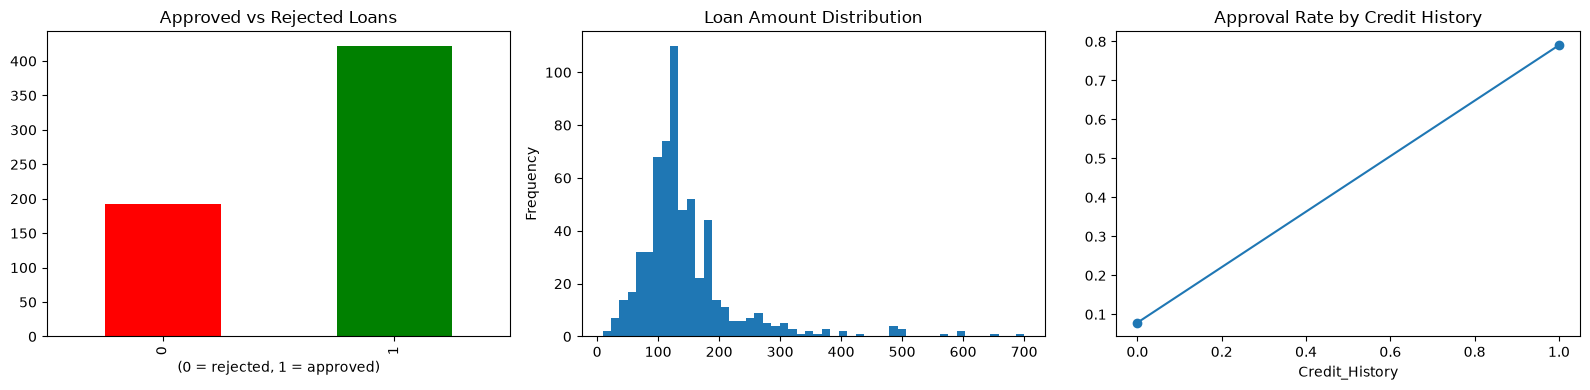

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df["approved"].value_counts().sort_index().plot(kind="bar", color=["red", "green"], ax=axes[0])
axes[0].set_title("Approved vs Rejected Loans")
axes[0].set_xlabel("(0 = rejected, 1 = approved)")
df["LoanAmount"].plot(kind="hist", bins=50, ax=axes[1])
axes[1].set_title("Loan Amount Distribution")
df.groupby("Credit_History")["approved"].mean().plot(kind="line", marker="o", ax=axes[2])
axes[2].set_title("Approval Rate by Credit History")
plt.tight_layout()
plt.show()

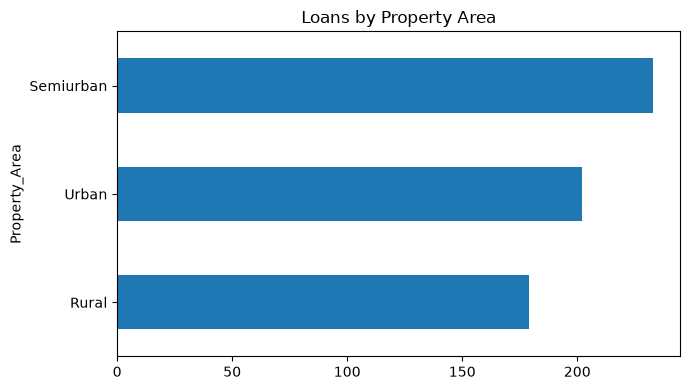

In [11]:
df["Property_Area"].value_counts().sort_values().plot(kind="barh", figsize=(7, 4), title="Loans by Property Area")
plt.tight_layout()
plt.show()

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (491, 16) Test: (123, 16)


In [13]:
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Naive Bayes": GaussianNB(),
    "KNN": KNeighborsClassifier(n_neighbors=11),
}

results = {}
confusions = {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    preds = model.predict(X_test_s)
    results[name] = {
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1": f1_score(y_test, preds),
    }
    confusions[name] = confusion_matrix(y_test, preds)
    print(name, results[name])
    print(classification_report(y_test, preds, target_names=['rejected (0)', 'approved (1)']))


print(pd.DataFrame(results).T.round(4))

Decision Tree {'Accuracy': 0.8211382113821138, 'Precision': 0.8247422680412371, 'Recall': 0.9411764705882353, 'F1': 0.8791208791208791}
              precision    recall  f1-score   support

rejected (0)       0.81      0.55      0.66        38
approved (1)       0.82      0.94      0.88        85

    accuracy                           0.82       123
   macro avg       0.82      0.75      0.77       123
weighted avg       0.82      0.82      0.81       123

Naive Bayes {'Accuracy': 0.8455284552845529, 'Precision': 0.83, 'Recall': 0.9764705882352941, 'F1': 0.8972972972972973}
              precision    recall  f1-score   support

rejected (0)       0.91      0.55      0.69        38
approved (1)       0.83      0.98      0.90        85

    accuracy                           0.85       123
   macro avg       0.87      0.76      0.79       123
weighted avg       0.86      0.85      0.83       123

KNN {'Accuracy': 0.8211382113821138, 'Precision': 0.8, 'Recall': 0.9882352941176471, 'F1':

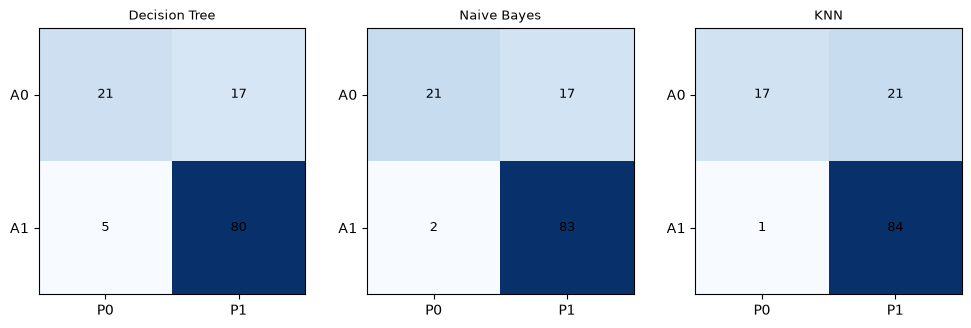

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, (name, cm) in zip(axes, confusions.items()):
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, str(v), ha="center", va="center", fontsize=9)
    ax.set_xticks([0, 1], ["P0", "P1"])
    ax.set_yticks([0, 1], ["A0", "A1"])
    ax.set_title(name, fontsize=9)
plt.tight_layout()
plt.show()

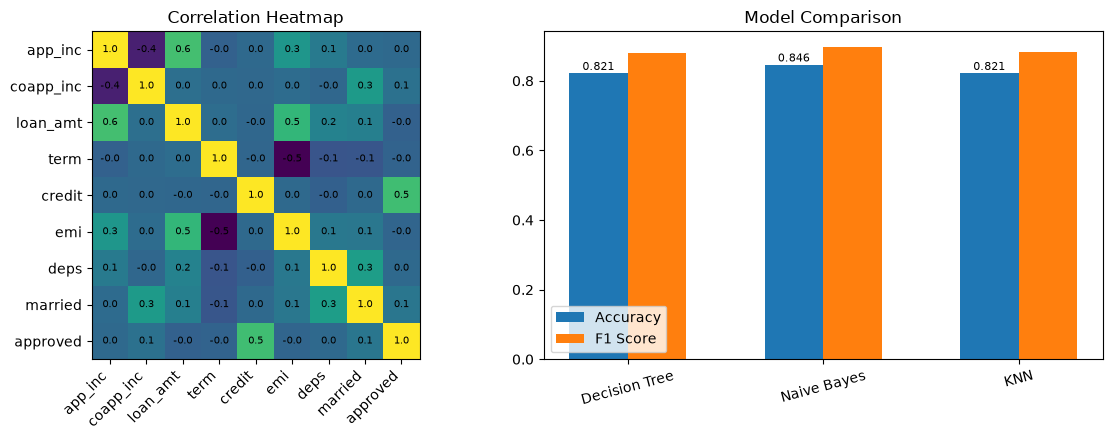

BEST MODEL: Naive Bayes Accuracy: 0.8455


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
corr_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term",
             "Credit_History", "emi", "num_dependents", "is_married", "approved"]
corr_labels = ["app_inc", "coapp_inc", "loan_amt", "term", "credit", "emi", "deps", "married", "approved"]
corr = df[corr_cols].corr()
axes[0].imshow(corr)
axes[0].set_xticks(range(9), corr_labels, rotation=45, ha="right")
axes[0].set_yticks(range(9), corr_labels)
for (i, j), v in np.ndenumerate(corr.values):
    axes[0].text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7)
axes[0].set_title("Correlation Heatmap")

x_pos = np.arange(len(results))
acc = [results[m]["Accuracy"] for m in results]
f1 = [results[m]["F1"] for m in results]
axes[1].bar(x_pos - 0.15, acc, 0.3, label="Accuracy")
axes[1].bar(x_pos + 0.15, f1, 0.3, label="F1 Score")
axes[1].set_xticks(x_pos, list(results.keys()), rotation=15)
axes[1].set_title("Model Comparison")
axes[1].legend()
for i, v in enumerate(acc):
    axes[1].text(i - 0.15, v + 0.01, f"{v:.3f}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

best = max(results, key=lambda m: results[m]["Accuracy"])
print("BEST MODEL:", best, "Accuracy:", f"{results[best]['Accuracy']:.4f}")